# Praktik Recipe AI Cookbook untuk Earth Sciences
## Tugas Kecerdasan Buatan — Python Notebook

Nama : Fathina Munifah

Nim : H061241060

## 1. Persiapan lingkungan

Library utama: `pandas` untuk data tabular, `numpy` untuk perhitungan numerik, dan `matplotlib` untuk visualisasi.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

OUTPUT_DIR = Path("hasil_recipe")
OUTPUT_DIR.mkdir(exist_ok=True)


Python: 3.13.2
pandas: 2.2.3
numpy: 2.3.3


## 2. Menyiapkan fixture data sintetis

Problem: praktik memerlukan file station CSV yang konsisten dan dapat diulang.

Specification: buat data harian selama 90 hari untuk tiga stasiun, dengan kolom date, station_id, rainfall_mm_day, dan temperature_c. Beberapa nilai sengaja dibuat kosong, duplikat, atau berada di luar rentang ilustratif agar recipe QC dapat diuji.

Provenance: data dibuat di notebook dengan random seed tetap; bukan data observasi.

In [2]:
rng = np.random.default_rng(42)
dates = pd.date_range("2026-01-01", periods=90, freq="D")
stations = {
    "ST01": {"rain_mean": 8.0, "temp_mean": 27.0},
    "ST02": {"rain_mean": 5.0, "temp_mean": 28.0},
    "ST03": {"rain_mean": 11.0, "temp_mean": 26.0},
}

rows = []
for station_id, params in stations.items():
    rain = rng.gamma(shape=1.8, scale=params["rain_mean"]/1.8, size=len(dates))
    rain[rng.random(len(dates)) < 0.35] = 0  # hari tanpa hujan
    temp = rng.normal(params["temp_mean"], 1.2, size=len(dates))
    for d, r, t in zip(dates, rain, temp):
        rows.append([d, station_id, round(float(r), 2), round(float(t), 2)])

df_raw = pd.DataFrame(rows, columns=[
    "date", "station_id", "rainfall_mm_day", "temperature_c"
])

# Sisipkan kasus uji QC secara sengaja
df_raw.loc[5, "rainfall_mm_day"] = np.nan
df_raw.loc[20, "temperature_c"] = np.nan
df_raw.loc[35, "rainfall_mm_day"] = -4.0
df_raw.loc[50, "temperature_c"] = 58.0
df_raw = pd.concat([df_raw, df_raw.iloc[[10]]], ignore_index=True)  # duplikat

csv_path = OUTPUT_DIR / "station_synthetic.csv"
df_raw.to_csv(csv_path, index=False)

print("File dibuat:", csv_path)
print("Jumlah baris:", len(df_raw))
df_raw.head()


File dibuat: hasil_recipe\station_synthetic.csv
Jumlah baris: 271


,date,station_id,rainfall_mm_day,temperature_c
0,2026-01-01,ST01,8.30,27.19
1,2026-01-02,ST01,11.45,27.42
2,2026-01-03,ST01,0.00,27.06
3,2026-01-04,ST01,6.43,27.00
4,2026-01-05,ST01,0.00,26.13


## 3. Praktik Recipe Buku R-IO-001 — Membaca dan Merangkum Station CSV

Problem: data stasiun tersimpan dalam CSV dan perlu dibaca serta diringkas sebelum analisis.

Minimal theory: CSV merupakan format tabular sederhana. pandas.DataFrame memudahkan pemeriksaan kolom, tipe data, jumlah record, dan statistik ringkas.

Specification / prompt praktik:
Baca file station CSV. Periksa nama kolom dan tipe data, konversi tanggal menjadi datetime, tampilkan jumlah record per stasiun, serta hitung statistik deskriptif curah hujan dan temperatur. Jangan mengubah file sumber.

Expected output: tabel inspeksi, jumlah record per stasiun, dan statistik deskriptif.

In [3]:
# Baca file; file sumber tetap dipertahankan
station = pd.read_csv(csv_path)
station["date"] = pd.to_datetime(station["date"], errors="coerce")

print("Ukuran data (baris, kolom):", station.shape)
print("\nInformasi kolom:")
station.info()

print("\nJumlah record per stasiun:")
display(station.groupby("station_id").size().rename("jumlah_record").to_frame())

print("\nStatistik deskriptif:")
display(station[["rainfall_mm_day", "temperature_c"]].describe())

print("\nLima baris pertama:")
display(station.head())


Ukuran data (baris, kolom): (271, 4)

Informasi kolom:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271 entries, 0 to 270
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             271 non-null    datetime64[ns]
 1   station_id       271 non-null    object        
 2   rainfall_mm_day  270 non-null    float64       
 3   temperature_c    270 non-null    float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 8.6+ KB

Jumlah record per stasiun:


,jumlah_record
station_id,
ST01,91
ST02,90
ST03,90



Statistik deskriptif:


,rainfall_mm_day,temperature_c
count,270.000000,270.000000
mean,4.602037,27.134704
std,5.975514,2.340287
min,-4.000000,23.380000
25%,0.000000,26.065000
50%,2.910000,27.005000
75%,7.350000,27.900000
max,31.750000,58.000000



Lima baris pertama:


,date,station_id,rainfall_mm_day,temperature_c
0,2026-01-01,ST01,8.30,27.19
1,2026-01-02,ST01,11.45,27.42
2,2026-01-03,ST01,0.00,27.06
3,2026-01-04,ST01,6.43,27.00
4,2026-01-05,ST01,0.00,26.13


### Interpretasi R-IO-001

Tabel jumlah record menunjukkan banyaknya catatan yang tersimpan untuk setiap stasiun. Statistik deskriptif memberikan gambaran nilai minimum, maksimum, rata-rata, dan sebaran curah hujan serta temperatur. Tahap ini merupakan pemeriksaan struktur dan ringkasan awal, belum menyatakan bahwa semua nilai valid secara ilmiah.

In [4]:
assert "station_id" in station.columns
assert "rainfall_mm_day" in station.columns
assert station["date"].notna().all()
print("CHECK R-IO-001: kolom utama tersedia dan tanggal berhasil dibaca.")


CHECK R-IO-001: kolom utama tersedia dan tanggal berhasil dibaca.


## 4. Praktik Recipe Buku R-QC-001 — Membuat Data Quality Summary

Problem: data dapat memiliki missing value, duplikasi, atau nilai di luar rentang pemeriksaan.

Minimal theory: Quality Control (QC) menandai gejala masalah data. Flag QC tidak otomatis menjelaskan penyebabnya dan tidak berarti record harus langsung dihapus.

Specification / prompt praktik:
> Buat ringkasan kualitas data yang memeriksa missing value, duplikasi berdasarkan stasiun dan tanggal, serta nilai curah hujan dan temperatur di luar rentang pemeriksaan. Pertahankan data mentah dan buat kolom flag secara terpisah.

Batas pemeriksaan ilustratif untuk latihan ini:
- Curah hujan: 0–500 mm/hari.
- Temperatur: 0–45 °C.
- Kunci duplikasi: kombinasi `station_id` dan `date`.

Rentang tersebut hanya aturan latihan, bukan standar universal untuk semua lokasi.

In [5]:
qc = station.copy()

qc["flag_missing_rain"] = qc["rainfall_mm_day"].isna()
qc["flag_missing_temp"] = qc["temperature_c"].isna()
qc["flag_rain_out_of_range"] = (
    qc["rainfall_mm_day"].notna()
    & ~qc["rainfall_mm_day"].between(0, 500)
)
qc["flag_temp_out_of_range"] = (
    qc["temperature_c"].notna()
    & ~qc["temperature_c"].between(0, 45)
)
qc["flag_duplicate_station_date"] = qc.duplicated(
    subset=["station_id", "date"], keep=False
)

flag_cols = [c for c in qc.columns if c.startswith("flag_")]
qc_summary = pd.DataFrame({
    "jumlah_flag": qc[flag_cols].sum(),
    "persentase_record": (qc[flag_cols].mean() * 100).round(2)
})
display(qc_summary)

print("Total record:", len(qc))
print("Record dengan minimal satu flag:",
      int(qc[flag_cols].any(axis=1).sum()))

# Simpan salinan berisi flag, bukan menimpa CSV mentah
qc_path = OUTPUT_DIR / "station_qc_flags.csv"
qc.to_csv(qc_path, index=False)
print("Hasil QC disimpan:", qc_path)


,jumlah_flag,persentase_record
flag_missing_rain,1,0.37
flag_missing_temp,1,0.37
flag_rain_out_of_range,1,0.37
flag_temp_out_of_range,1,0.37
flag_duplicate_station_date,2,0.74


Total record: 271
Record dengan minimal satu flag: 6
Hasil QC disimpan: hasil_recipe\station_qc_flags.csv


### Melihat record yang ditandai QC

Tabel berikut membantu menelusuri baris yang memiliki satu atau lebih flag. Data asli tidak dihapus.

In [6]:
flagged_records = qc.loc[qc[flag_cols].any(axis=1),
                           ["date", "station_id", "rainfall_mm_day",
                            "temperature_c"] + flag_cols]
display(flagged_records.head(15))


,date,station_id,rainfall_mm_day,temperature_c,flag_missing_rain,flag_missing_temp,flag_rain_out_of_range,flag_temp_out_of_range,flag_duplicate_station_date
5,2026-01-06,ST01,NaN,27.38,True,False,False,False,False
10,2026-01-11,ST01,0.00,26.08,False,False,False,False,True
20,2026-01-21,ST01,0.00,NaN,False,True,False,False,False
35,2026-02-05,ST01,-4.00,25.16,False,False,True,False,False
50,2026-02-20,ST01,4.78,58.00,False,False,False,True,False
270,2026-01-11,ST01,0.00,26.08,False,False,False,False,True


### Interpretasi R-QC-001

Ringkasan QC menunjukkan jenis dan jumlah masalah yang sengaja dimasukkan ke fixture, misalnya nilai kosong, duplikasi stasiun–tanggal, atau nilai di luar rentang pemeriksaan. Baris yang ditandai perlu ditinjau lebih lanjut. Karena data ini sintetis, flag yang muncul merupakan hasil skenario pengujian, bukan temuan kondisi cuaca sebenarnya.

In [7]:
# Check: pastikan kasus uji yang ditanam terdeteksi
assert qc["flag_missing_rain"].sum() >= 1
assert qc["flag_missing_temp"].sum() >= 1
assert qc["flag_rain_out_of_range"].sum() >= 1
assert qc["flag_temp_out_of_range"].sum() >= 1
assert qc["flag_duplicate_station_date"].sum() >= 2
print("CHECK R-QC-001: seluruh jenis kasus uji berhasil ditandai.")


CHECK R-QC-001: seluruh jenis kasus uji berhasil ditandai.


## 5. Praktik Recipe Buku R-VIS-001 — Membuat Time-Series Figure yang Informatif

Problem: time series perlu memperlihatkan perubahan pengamatan tanpa menghubungkan titik yang hilang.

Specification / prompt praktik:
> Buat grafik curah hujan harian terhadap waktu untuk setiap stasiun. Cantumkan satuan pada sumbu, gunakan panel terpisah, dan biarkan missing value sebagai gap. Simpan figure PNG. Jangan mengubah data.

Expected output:figure time series yang memiliki label, legenda/judul, dan satuan yang jelas.

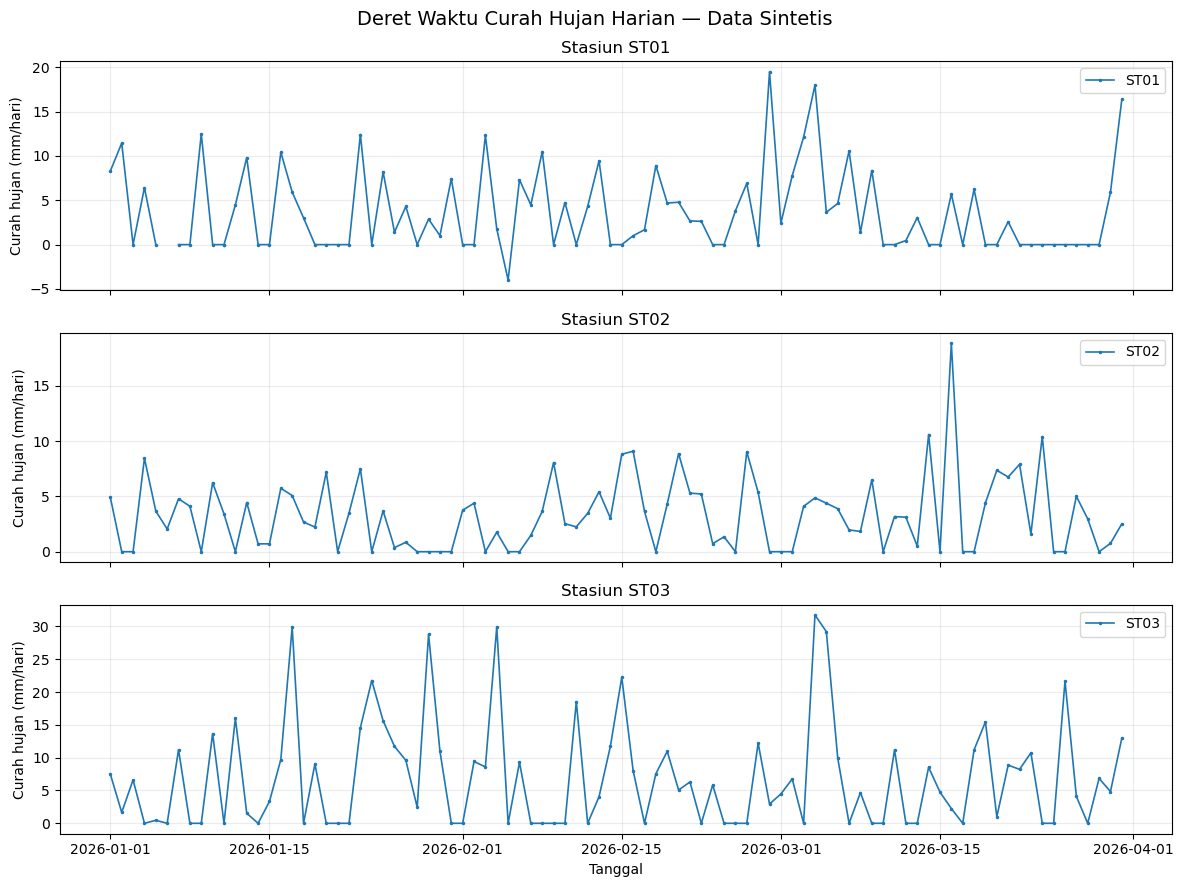

Figure disimpan: hasil_recipe\time_series_rainfall.png


In [8]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

for ax, (station_id, group) in zip(axes, station.groupby("station_id")):
    group = group.sort_values("date")
    ax.plot(group["date"], group["rainfall_mm_day"],
            linewidth=1.2, marker=".", markersize=3,
            label=station_id)
    ax.set_ylabel("Curah hujan (mm/hari)")
    ax.set_title(f"Stasiun {station_id}")
    ax.grid(True, alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Tanggal")
fig.suptitle("Deret Waktu Curah Hujan Harian — Data Sintetis", fontsize=14)
fig.tight_layout()
figure_path = OUTPUT_DIR / "time_series_rainfall.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure disimpan:", figure_path)


### Interpretasi R-VIS-001

Grafik memperlihatkan variasi curah hujan harian pada tiga stasiun selama periode simulasi. Perbedaan pola antarpanel dapat diamati tanpa mencampur skala waktu setiap stasiun. Bagian yang kosong pada data tidak diisi secara otomatis sehingga gap tetap terlihat. Grafik ini bersifat eksploratif dan tidak mewakili kondisi pengamatan lapangan.

In [9]:
# Check: file figure tersimpan dan data sumber tidak berubah jumlah barisnya
assert figure_path.exists()
assert len(station) == len(df_raw)
print("CHECK R-VIS-001: figure tersimpan; jumlah record tetap.")


CHECK R-VIS-001: figure tersimpan; jumlah record tetap.


## 6. Recipe buatan sendiri R-OWN-001 — Deteksi Anomali Curah Hujan terhadap Baseline Stasiun

Problem: ingin mengidentifikasi hari dengan curah hujan yang jauh lebih tinggi daripada pola umum stasiun yang sama.

Ide recipe: hitung baseline berupa median curah hujan tiap stasiun. Hitung Median Absolute Deviation (MAD), lalu tandai nilai yang lebih besar dari median + 3 × MAD. Nilai hilang tidak digunakan dalam perhitungan.

Rumus:

$$MAD = \operatorname(|x_i - \operatorname(x)|)$$

$$\text = \operatorname(x) + 3 \times MAD$$


In [11]:
def detect_rain_anomaly(data, multiplier=3.0):
    """Deteksi nilai tinggi terhadap median + multiplier*MAD per stasiun."""
    result = data.copy()
    result["rain_anomaly"] = False
    baseline_rows = []

    for station_id, idx in result.groupby("station_id").groups.items():
        values = result.loc[idx, "rainfall_mm_day"].dropna()
        if values.empty:
            continue

        median_value = values.median()
        mad = (values - median_value).abs().median()
        upper_limit = median_value + multiplier * mad

        valid = result.loc[idx, "rainfall_mm_day"].notna()
        result.loc[idx, "rain_anomaly"] = (
            valid & (result.loc[idx, "rainfall_mm_day"] > upper_limit)
        )

        baseline_rows.append({
            "station_id": station_id,
            "median_mm_day": median_value,
            "MAD": mad,
            "upper_limit_mm_day": upper_limit,
            "n_valid": len(values)
        })

    baseline = pd.DataFrame(baseline_rows)
    return result, baseline

anomaly_data, baseline_table = detect_rain_anomaly(station, multiplier=3)
display(baseline_table.round(2))

anomaly_path = OUTPUT_DIR / "rainfall_anomaly_results.csv"
anomaly_data.to_csv(anomaly_path, index=False)
print("Hasil deteksi disimpan:", anomaly_path)


,station_id,median_mm_day,MAD,upper_limit_mm_day,n_valid
0,ST01,1.54,1.54,6.16,90
1,ST02,3.00,2.39,10.17,90
2,ST03,4.72,4.72,18.86,90


Hasil deteksi disimpan: hasil_recipe\rainfall_anomaly_results.csv


### Visualisasi hasil recipe buatan sendiri

Titik yang ditandai merupakan nilai yang melewati batas atas hasil perhitungan recipe. Penandaan ini adalah indikasi statistik untuk ditinjau, bukan bukti otomatis bahwa telah terjadi cuaca ekstrem.

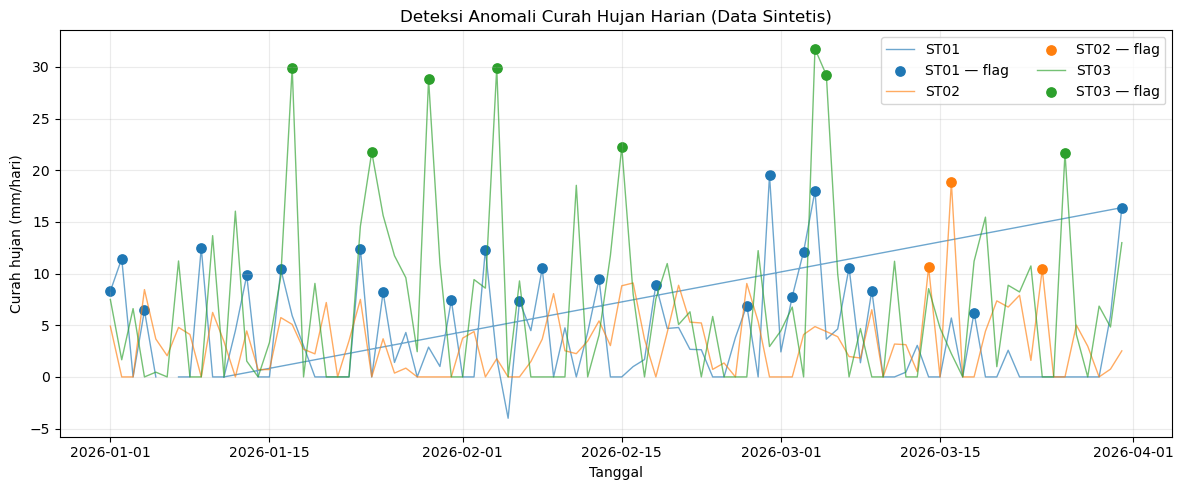

Jumlah flag anomali: 34
Figure disimpan: hasil_recipe\rainfall_anomaly.png


In [12]:
fig, ax = plt.subplots(figsize=(12, 5))

for station_id, group in anomaly_data.groupby("station_id"):
    ax.plot(group["date"], group["rainfall_mm_day"],
            linewidth=1, alpha=0.65, label=station_id)
    flagged = group[group["rain_anomaly"]]
    ax.scatter(flagged["date"], flagged["rainfall_mm_day"],
               s=45, marker="o", label=f"{station_id} — flag")

ax.set_title("Deteksi Anomali Curah Hujan Harian (Data Sintetis)")
ax.set_xlabel("Tanggal")
ax.set_ylabel("Curah hujan (mm/hari)")
ax.grid(True, alpha=0.25)
ax.legend(ncol=2)
fig.tight_layout()
anomaly_fig_path = OUTPUT_DIR / "rainfall_anomaly.png"
fig.savefig(anomaly_fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("Jumlah flag anomali:", int(anomaly_data["rain_anomaly"].sum()))
print("Figure disimpan:", anomaly_fig_path)


### Interpretasi R-OWN-001

Recipe menghitung baseline secara terpisah untuk setiap stasiun agar perbandingan tidak langsung mencampur karakteristik ketiga stasiun. Hari yang curah hujannya melampaui median + 3 MAD diberi flag. Hasil perlu diperiksa bersama metadata, kualitas sensor, dan informasi meteorologi lain sebelum dibuat kesimpulan.

Keunikan recipe sendiri: recipe ini menggabungkan baseline robust berbasis median dan MAD, menghasilkan tabel parameter tiap stasiun, menambahkan flag ke salinan data, serta menyimpan tabel dan grafik hasil.

In [13]:
# Check sederhana untuk recipe sendiri
assert "rain_anomaly" in anomaly_data.columns
assert baseline_table["station_id"].nunique() == station["station_id"].nunique()
assert anomaly_data["rain_anomaly"].notna().all()
print("CHECK R-OWN-001: fungsi berjalan dan baseline tersedia untuk setiap stasiun.")


CHECK R-OWN-001: fungsi berjalan dan baseline tersedia untuk setiap stasiun.
